In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
data = pd.read_csv(r"C:\Users\Banavand-Pc\Downloads\survey lung cancer.csv")

In [6]:
data.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


### Important columns for search:
* GENDER
* AGE
* SMOKING
* ANXIETY
* ALCOHOL CONSUMING
* COUGHING
* CHEST PAIN

### Important columns for data processing:
* PEER_PRESSURE
* CHRONIC DISEASE
* FATIGUE
* ALLERGY
* SWALLOWING DIFFICULTY
* SHORTNESS OF BREATH

### Target column:
* LUNG_CANCER

- 1 = No
- 2 = Yes

In [142]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GENDER                 309 non-null    str  
 1   AGE                    309 non-null    int64
 2   SMOKING                309 non-null    int64
 3   YELLOW_FINGERS         309 non-null    int64
 4   ANXIETY                309 non-null    int64
 5   PEER_PRESSURE          309 non-null    int64
 6   CHRONIC DISEASE        309 non-null    int64
 7   FATIGUE                309 non-null    int64
 8   ALLERGY                309 non-null    int64
 9   WHEEZING               309 non-null    int64
 10  ALCOHOL CONSUMING      309 non-null    int64
 11  COUGHING               309 non-null    int64
 12  SHORTNESS OF BREATH    309 non-null    int64
 13  SWALLOWING DIFFICULTY  309 non-null    int64
 14  CHEST PAIN             309 non-null    int64
 15  LUNG_CANCER            309 non-null    str  
dtypes

In [143]:
data.isnull().sum()

GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64

In [144]:
data.GENDER.value_counts()

GENDER
M    162
F    147
Name: count, dtype: int64

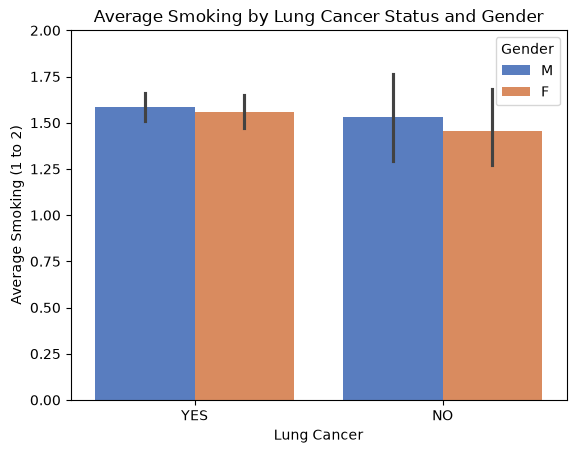

In [145]:
sns.barplot(data=data, x='LUNG_CANCER', y='SMOKING', hue='GENDER', palette='muted')
plt.title('Average Smoking by Lung Cancer Status and Gender')
plt.ylabel('Average Smoking (1 to 2)')
plt.xlabel('Lung Cancer')
plt.yticks(np.arange(0.0, 2.1, 0.25))
plt.legend(title='Gender')
plt.show()

* The SMOKING variable has low discriminative power, as its mean does not differ significantly between healthy individuals and patients.

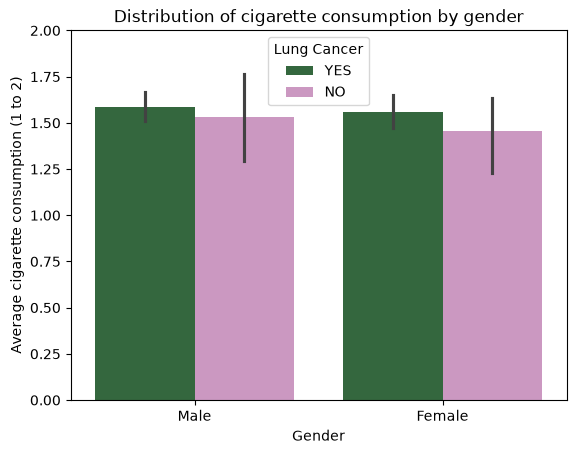

In [146]:
sns.barplot(data=data, x='GENDER', y='SMOKING', hue='LUNG_CANCER', palette='cubehelix')
plt.title('Distribution of cigarette consumption by gender')
plt.ylabel('Average cigarette consumption (1 to 2)')
plt.xlabel('Gender')
plt.yticks(np.arange(0.0, 2.1, 0.25))
plt.xticks(ticks=[0, 1], labels=['Male', 'Female'])
plt.legend(title='Lung Cancer')  # 1:No | 2:Yes
plt.show()

In [147]:
smoking_filter = data[data['SMOKING'] == 2]

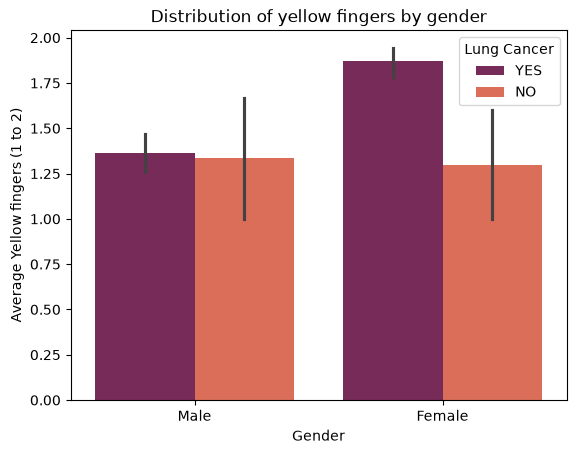

In [148]:
sns.barplot(data=smoking_filter, x='GENDER', y='YELLOW_FINGERS', hue='LUNG_CANCER', palette='rocket')
plt.title('Distribution of yellow fingers by gender')
plt.ylabel('Average Yellow fingers (1 to 2)')
plt.xlabel('Gender')
plt.yticks(np.arange(0.0, 2.1, 0.25))
plt.xticks(ticks=[0, 1], labels=['Male', 'Female'])
plt.legend(title='Lung Cancer')  # 1:No | 2:Yes
plt.show()

* Very small sample size in the subgroup of non-affected, smoking women

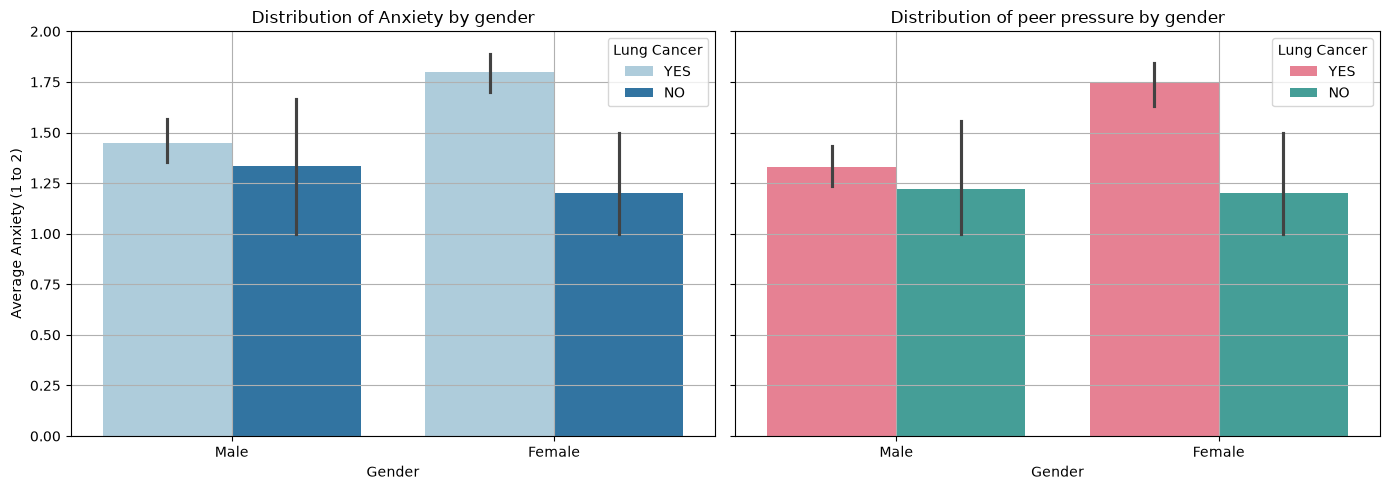

In [149]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.barplot(data=smoking_filter, x='GENDER', y='ANXIETY',
             hue='LUNG_CANCER', palette='Paired', ax=axes[0])

axes[0].set_title('Distribution of Anxiety by gender')
axes[0].set_ylabel('Average Anxiety (1 to 2)')
axes[0].set_xlabel('Gender')
axes[0].set_yticks(np.arange(0.0, 2.1, 0.25))
axes[0].set_xticks(ticks=[0, 1], labels=['Male', 'Female'])
axes[0].grid()
axes[0].legend(title='Lung Cancer')  # 1:No | 2:Yes


sns.barplot(data=smoking_filter, x='GENDER', y='PEER_PRESSURE',
             hue='LUNG_CANCER', palette='husl', ax=axes[1])

axes[1].set_title('Distribution of peer pressure by gender')
axes[1].set_ylabel('Average Peer Pressure (1 to 2)')
axes[1].set_xlabel('Gender')
axes[1].set_yticks(np.arange(0.0, 2.1, 0.25))
axes[1].set_xticks(ticks=[0, 1], labels=['Male', 'Female'])
axes[1].grid()
axes[1].legend(title='Lung Cancer')

plt.tight_layout()
plt.show()

* The PEER_PRESSURE chart exhibits a significantly more stable and logical state, and can serve as a benchmark.

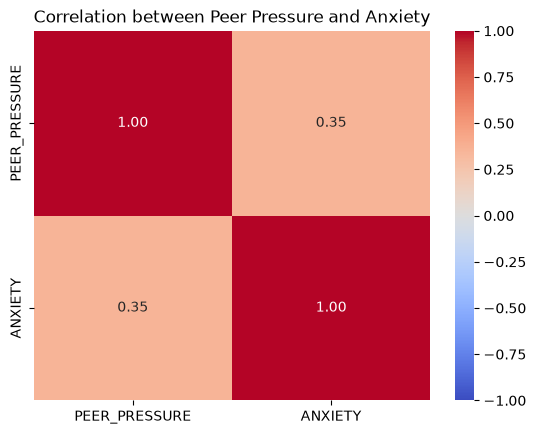

In [150]:
corr_matrix = smoking_filter[['PEER_PRESSURE', 'ANXIETY']].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation between Peer Pressure and Anxiety')
plt.show()

* The degree of similarity between these two charts: "Anxiety by gender" and "Peer pressure by gender."

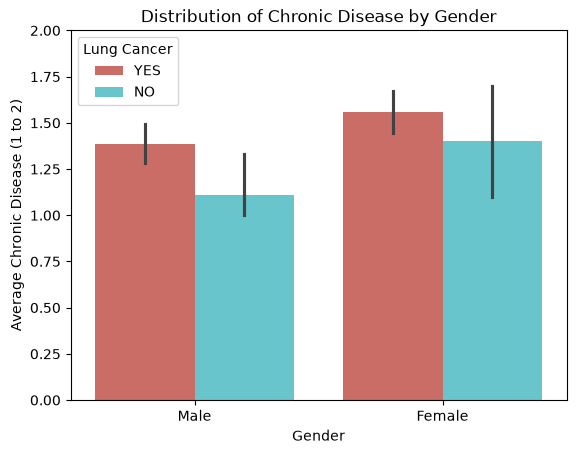

In [151]:
sns.barplot(data=smoking_filter, x='GENDER', y='CHRONIC DISEASE', hue='LUNG_CANCER', palette='hls')
plt.title('Distribution of Chronic Disease by Gender')
plt.ylabel('Average Chronic Disease (1 to 2)')
plt.xlabel('Gender')
plt.yticks(np.arange(0.0, 2.1, 0.25))
plt.xticks(ticks=[0, 1], labels=['Male', 'Female'])
plt.legend(title='Lung Cancer')
plt.show()

* Chronic illness is more prevalent among women in this dataset; however, this alone does not prove that it acts as a stronger exacerbating factor for them than for men, given that even the healthy women within this statistical population exhibited a high rate of chronic illness (1.4).

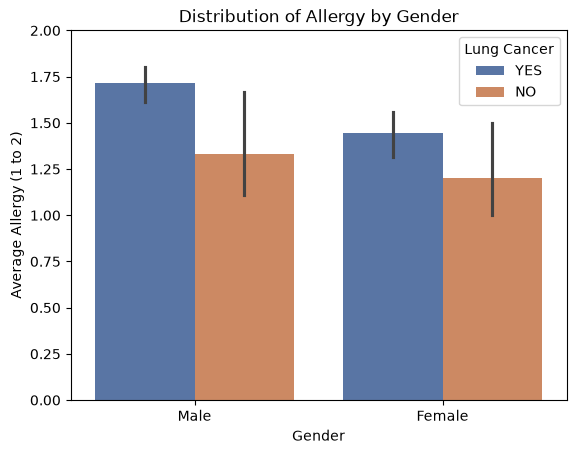

In [152]:
sns.barplot(data=smoking_filter, x='GENDER', y='ALLERGY ', hue='LUNG_CANCER', palette='deep')
plt.title('Distribution of Allergy by Gender')
plt.ylabel('Average Allergy (1 to 2)')
plt.xlabel('Gender')
plt.yticks(np.arange(0.0, 2.1, 0.25))
plt.xticks(ticks=[0, 1], labels=['Male', 'Female'])
plt.legend(title='Lung Cancer')
plt.show()

* The allergy column is highly significant; the clear separation, the established order within both groups, and the reduced error rate—all three factors underscore the importance of this feature.

In [168]:
data.SMOKING.value_counts()

SMOKING
2    174
1    135
Name: count, dtype: int64

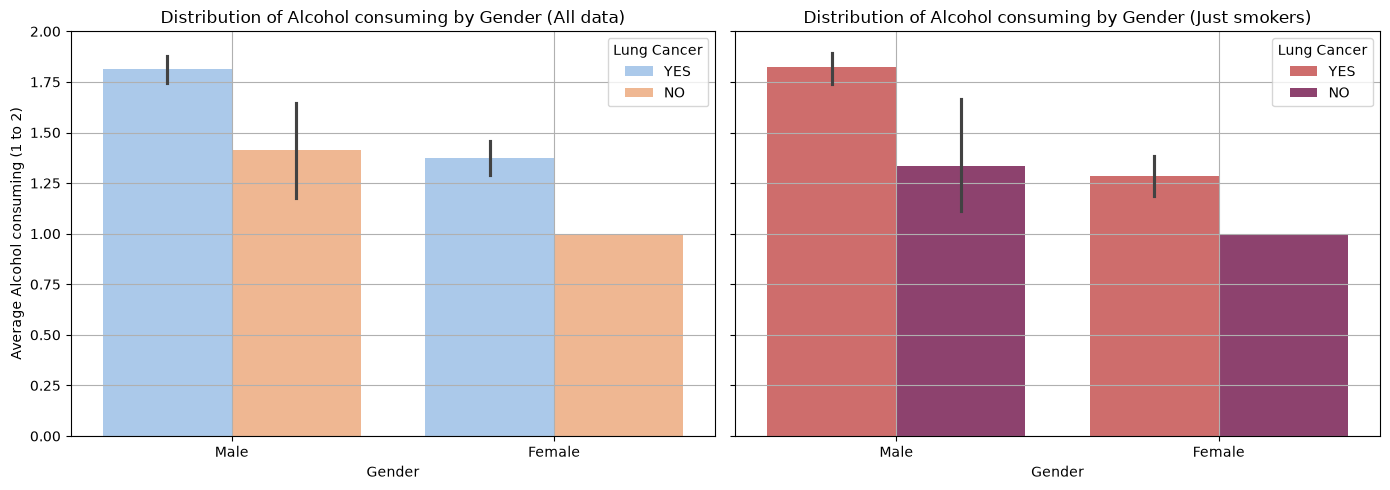

In [169]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)


sns.barplot(data=data, x='GENDER', y='ALCOHOL CONSUMING',
             hue='LUNG_CANCER', palette='pastel', ax=axes[0])

axes[0].set_title('Distribution of Alcohol consuming by Gender (All data)')
axes[0].set_ylabel('Average Alcohol consuming (1 to 2)')
axes[0].set_xlabel('Gender')
axes[0].set_yticks(np.arange(0.0, 2.1, 0.25))
axes[0].set_xticks(ticks=[0, 1], labels=['Male', 'Female'])
axes[0].grid()
axes[0].legend(title='Lung Cancer')


sns.barplot(data=smoking_filter, x='GENDER', y='ALCOHOL CONSUMING',
             hue='LUNG_CANCER', palette='flare', ax=axes[1])

axes[1].set_title('Distribution of Alcohol consuming by Gender (Just smokers)')
axes[1].set_ylabel('Average Alcohol consuming (1 to 2)')
axes[1].set_xlabel('Gender')
axes[1].set_yticks(np.arange(0.0, 2.1, 0.25))
axes[1].set_xticks(ticks=[0, 1], labels=['Male', 'Female'])
axes[1].grid()
axes[1].legend(title='Lung Cancer')


plt.tight_layout()
plt.show()

* The relationship between alcohol consumption and lung cancer remains consistent in both its intensity and pattern, regardless of whether the individual is a smoker or a non-smoker.

* A value of 1 among the women in both groups indicates that none of the healthy women in this study—whether smokers or non-smokers—consumed alcohol.

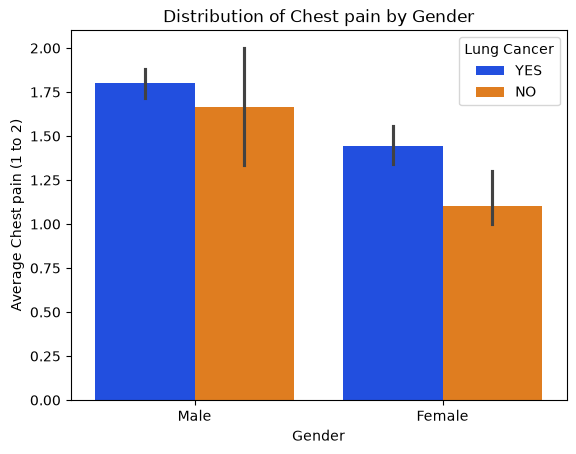

In [154]:
sns.barplot(data=smoking_filter, x='GENDER', y='CHEST PAIN', hue='LUNG_CANCER', palette='bright')
plt.title('Distribution of Chest pain by Gender')
plt.ylabel('Average Chest pain (1 to 2)')
plt.xlabel('Gender')
plt.yticks(np.arange(0.0, 2.1, 0.25))
plt.xticks(ticks=[0, 1], labels=['Male', 'Female'])
plt.legend(title='Lung Cancer')
plt.show()

* While chest pain is, in medical theory, a primary symptom, in this dataset—given this level of granular breakdown—it functions more like a signal riddled with errors than a clean, reliable metric.

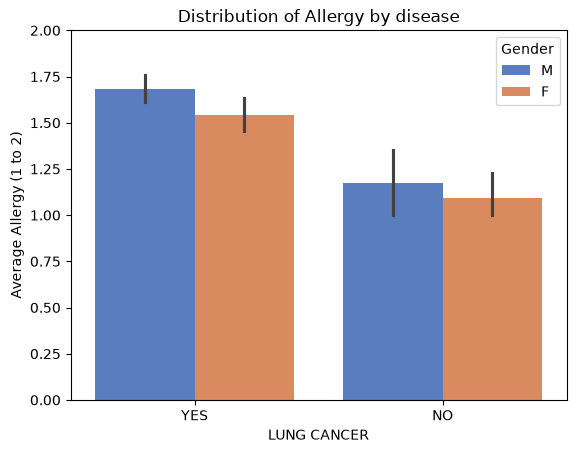

In [156]:
sns.barplot(data=data, x='LUNG_CANCER', y='ALLERGY ', hue='GENDER', palette='muted')
plt.title('Distribution of Allergy by disease')
plt.ylabel('Average Allergy (1 to 2)')
plt.xlabel('LUNG CANCER')
plt.yticks(np.arange(0.0, 2.1, 0.25))
plt.legend(title='Gender')
plt.show()

* The ALLERGY variant possesses very high discriminative power.

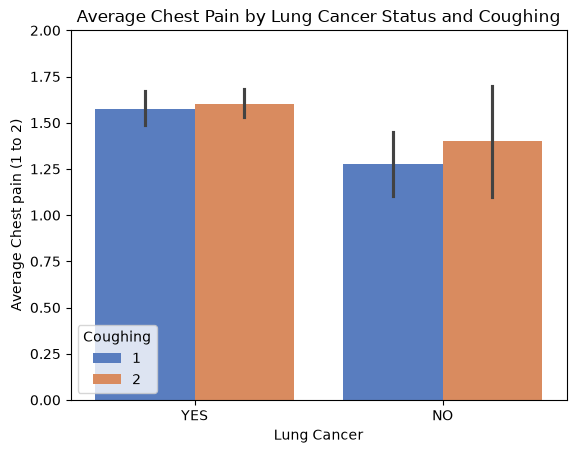

In [157]:
sns.barplot(data=data, x='LUNG_CANCER', y='CHEST PAIN', hue='COUGHING', palette='muted')
plt.title('Average Chest Pain by Lung Cancer Status and Coughing')
plt.ylabel('Average Chest pain (1 to 2)')
plt.xlabel('Lung Cancer')
plt.yticks(np.arange(0.0, 2.1, 0.25))
plt.legend(title='Coughing')
plt.show()

* In this combination, these two clinical features (chest pain and coughing) not only introduce redundancy and noise, but they also fail to provide any clear discrimination with respect to the target variable.

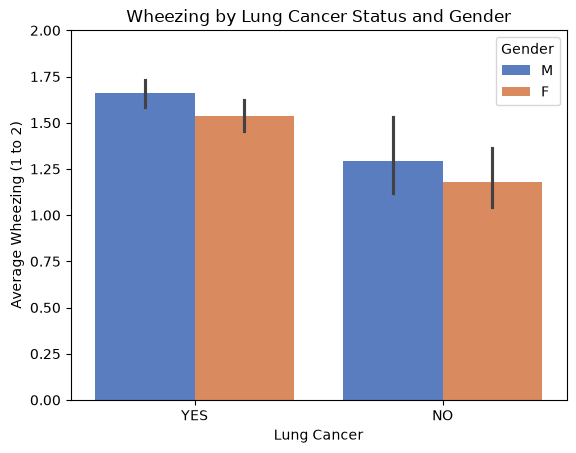

In [182]:
sns.barplot(data=data, x='LUNG_CANCER', y='WHEEZING', hue='GENDER', palette='muted')
plt.title('Wheezing by Lung Cancer Status and Gender')
plt.ylabel('Average Wheezing (1 to 2)')
plt.xlabel('Lung Cancer')
plt.yticks(np.arange(0.0, 2.1, 0.25))
plt.legend(title='Gender')
plt.show()

##### Selected Features:
- Wheezing
- Allergy
- Alcohol consumption
- Peer pressure

##### Basic Features:
- Age
- Gender

##### Excluded Features:
- Smoking
- Anxiety
- Chest pain
- ...